# Eject! Notebook 2: Real terrain and the hazard map

**Goal: find where blocks really land, then draw the danger zone in QGIS.**

This is **Notebook 2 of 2** in the workshop.

Real volcanoes are **not flat**. The slope rises near the vent and falls away. This notebook
uses the **real shape** of your volcano to find where blocks actually hit the ground 
in four directions. Then we will take those distances into QGIS for our hazard maps.

## To do:

- Load the real slope of the volcano in four directions.
- Find the **impact distance** in each direction (North, South, East, West).
- Export the impact points and build a hazard zone in QGIS.


## What is a volcanic ballistic projectile (VBP)?

The objects that Eject! models have a proper name: **volcanic ballistic projectiles (VBPs)**.

- A VBP is any **pyroclast** (a fragment ejected by an eruption) **larger than 6.4 cm**
  in length (think about the size of a tennis ball).
- There are two kinds: **blocks** (solid, cold rock) and **bombs** (still soft and *molten* when
  thrown).
- A VBP flies on its own curved path, like a thrown ball. Eject! draws that path (simplified).
- VBPs are a common hazard in **explosive** eruptions, and are most dangerous **within 5 km** of
  the vent (Taddeucci et al., 2017; Brown et al., 2017).


## How to use this notebook

- Run the cells **from top to bottom**. Click a cell, then press **Shift + Enter** OR click a cell and press the 'play' button.
- A cell often needs the result of an earlier cell, so DO NOT skip ahead.
- A **CHECK** note tells you what you should see when a step works.
- A **TIP** note gives advice about a common mistake.


## Words to know

A word bank is provided below. You can also refer to the word document.

| Word | Simple definition |
|------|----------------|
| **Vent** | The opening where the eruption comes out. The center of the map: point (0, 0). |
| **VBP** | *Volcanic ballistic projectile*, a thrown rock larger than 6.4 cm. Includes blocks and bombs. |
| **Block** | A *solid* (cold, hard) VBP. |
| **Bomb** | A *molten* (still soft and hot) VBP. |
| **Pyroclast** | Any piece of rock thrown out by an eruption. |
| **Ejection angle** | The launch angle above the ground, in degrees (°). Example: 45°. |
| **Initial velocity** | The launch speed, in meters per second (m/s). |
| **Diameter** | The width of the block, in meters (m). A bigger block is heavier. |
| **Trajectory** | The curved flight path of the block through the air. |
| **Impact point** | Where the block hits the ground. The landing spot. |
| **Hazard zone** | The area on a map that blocks can reach. The danger zone. |

## Please cite Eject! if you use it

- **Mastin, L.G. (2001).** *A simple calculator of ballistic trajectories for blocks ejected
  during volcanic eruptions.* U.S. Geological Survey Open-File Report 01-45, 16 p.
  https://pubs.usgs.gov/of/2001/0045/
- **Strehlow, K., Mastin, L.G., Sandri, L., Gottsmann, J.H., Kilgour, G., Rust, A.C., &
  Tonini, R. (2019).** *Eject! for Matlab.* https://vhub.org/resources/4543



## Setup

Run this cell once. It loads the libraries and the EJECT! function.

In [33]:
# Load the libraries and the EJECT! function
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# The Eject! trajectory function (ships with the workshop files)
from eject import eject

# Plot style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11

print("Setup complete. The eject() function is ready.")

Setup complete. The eject() function is ready.


## Part 1: Why the real shape matters

On flat ground, a block can fly a long way before it crosses an imaginary flat line. On a real
volcano, the **rising slope** stops the block much sooner. So the impact is **closer** to the
vent and it is **different in each direction**, because each slope is different.

The cells below load the real slope of your volcano in four directions.


In [34]:
# Load topography data
topography_file = 'Topography.xlsx'
df = pd.read_excel(topography_file, sheet_name='') # type the GVP volcano name within the ''

print("Topography data loaded!")
print(f"\nData shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head(10))

Topography data loaded!

Data shape: (168, 8)

Columns: ['x_east', 'topography_east', 'x_north', 'topography_north', 'x_west', 'topography_west', 'x_south', 'topography_south']

First few rows:
   x_east  topography_east  x_north  topography_north  x_west  \
0       0      1595.268066        0       1595.268066       0   
1      30      1588.914055       30       1589.383058      30   
2      60      1573.326544       60       1579.470318      60   
3      90      1555.666440       90       1566.295230      90   
4     120      1538.372711      120       1550.240005     120   
5     150      1521.710907      150       1532.183105     150   
6     180      1505.319255      180       1511.497792     180   
7     210      1489.355688      210       1491.140825     210   
8     240      1474.502562      240       1472.367870     240   
9     270      1461.578044      270       1455.209000     270   

   topography_west  x_south  topography_south  
0      1595.268066        0       1595.268

In [36]:
# Extract topography profiles for each direction
directions = {
    'East': {'x': df['x_east'].dropna().values, 'z': df['topography_east'].dropna().values},
    'West': {'x': df['x_west'].dropna().values, 'z': df['topography_west'].dropna().values},
    'North': {'x': df['x_north'].dropna().values, 'z': df['topography_north'].dropna().values},
    'South': {'x': df['x_south'].dropna().values, 'z': df['topography_south'].dropna().values}
}

# Vent elevation (summit)
vent_elevation = 1595  # meters above sea level. Change this for your volcano (look at the CSAV_Generic_DEM.ipynb file)

# Convert topography so vent is at z=0
for direction in directions:
    directions[direction]['z'] = directions[direction]['z'] - vent_elevation

print(f"✓ Topography profiles extracted for {len(directions)} directions")
print(f"\nVent elevation: {vent_elevation} m above sea level")
print(f"All elevations adjusted so vent is at z=0")

✓ Topography profiles extracted for 4 directions

Vent elevation: 1595 m above sea level
All elevations adjusted so vent is at z=0


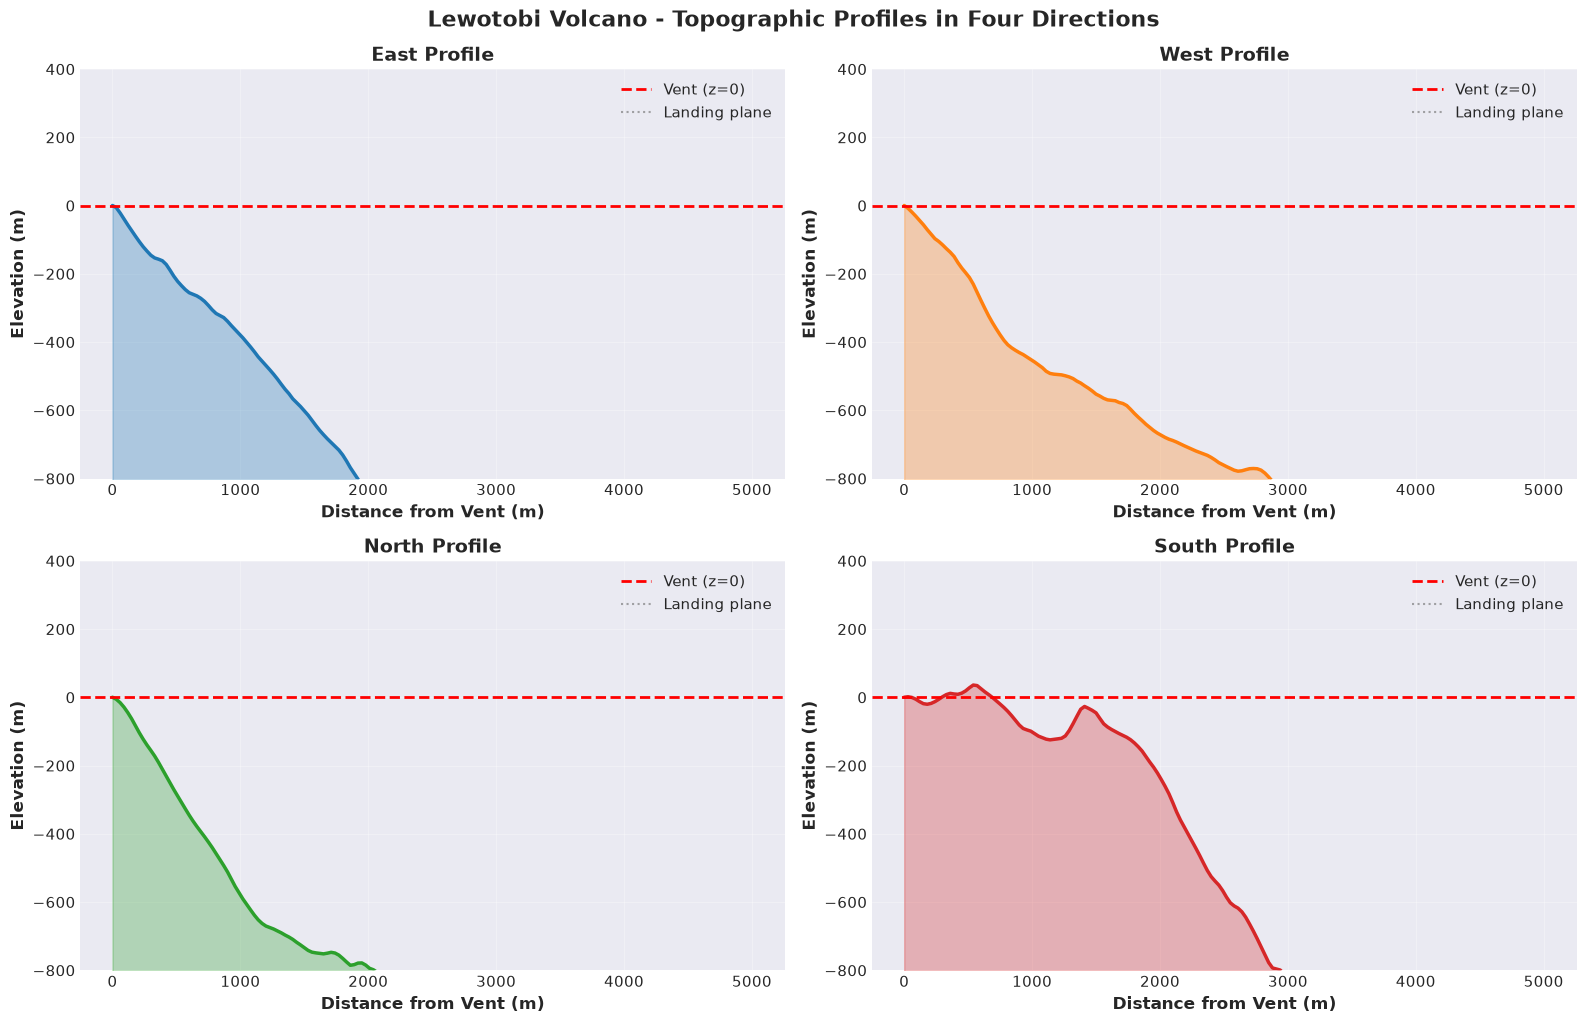


✓ Topography profiles plotted!


In [37]:
# Plot all topography profiles
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

colors = {'East': '#1f77b4', 'West': '#ff7f0e', 'North': '#2ca02c', 'South': '#d62728'}

for idx, (dir_name, data) in enumerate(directions.items()):
    ax = axes[idx]
    ax.plot(data['x'], data['z'], linewidth=2.5, color=colors[dir_name])
    ax.fill_between(data['x'], data['z'], -1500, alpha=0.3, color=colors[dir_name])
    ax.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Vent (z=0)')
    ax.axhline(y=-1000, color='gray', linestyle=':', linewidth=1.5, alpha=0.7, label='Landing plane')
    ax.set_xlabel('Distance from Vent (m)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Elevation (m)', fontsize=12, fontweight='bold')
    ax.set_title(f'{dir_name} Profile', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_ylim(-800, 400)

plt.tight_layout()
plt.suptitle('Name of Volcano - Topographic Profiles in Four Directions', 
             fontsize=16, fontweight='bold', y=1.02) # make sure you enter your volcano name
plt.show()

print("\n✓ Topography profiles plotted!")

> **CHECK:** you should see four slope profiles (East, West, North, South). The vent is at
> the top (z = 0), and the ground falls away from it.

### Finding the true impact point

The function below moves along a trajectory until it drops **below** the ground surface. That
crossing point is the real impact point.


In [38]:
def find_impact_point(traj_x, traj_z, topo_x, topo_z):
    """
    Find where a trajectory intersects with topography.
    
    Args:
        traj_x: trajectory x-coordinates
        traj_z: trajectory z-coordinates
        topo_x: topography x-coordinates
        topo_z: topography z-coordinates
    
    Returns:
        impact_x: x-coordinate of impact
        impact_z: z-coordinate of impact
    """
    # Create interpolation function for topography
    topo_interp = interp1d(topo_x, topo_z, kind='linear', 
                           bounds_error=False, fill_value='extrapolate')
    
    # Find where trajectory crosses topography
    for i in range(1, len(traj_z)):
        topo_height = topo_interp(traj_x[i])
        if traj_z[i] < topo_height:
            # Linear interpolation for more accurate impact point
            impact_x = traj_x[i-1] + (traj_x[i] - traj_x[i-1]) / 2
            impact_z = traj_z[i-1] + (traj_z[i] - traj_z[i-1]) / 2
            return impact_x, impact_z
    
    # If no intersection found, return last point
    return traj_x[-1], traj_z[-1]

print("✓ Impact detection function defined")

✓ Impact detection function defined


In [39]:
# Calculate a sample trajectory
angle = 45.0      # degrees
velocity = 100.0  # m/s
diameter = 0.5    # m

print(f"Calculating trajectory with:")
print(f"  Angle: {angle}°")
print(f"  Velocity: {velocity} m/s")
print(f"  Diameter: {diameter} m")
print()

traj = eject(angle, velocity, diameter)
traj_x = traj[:, 0]
traj_z = traj[:, 1]

print(f"✓ Trajectory calculated")
print(f"  Landing plane distance: {traj_x[-1]:.1f} m")
print(f"  Maximum height: {np.max(traj_z):.1f} m")

Calculating trajectory with:
  Angle: 45.0°
  Velocity: 100.0 m/s
  Diameter: 0.5 m

✓ Trajectory calculated
  Landing plane distance: 1266.1 m
  Maximum height: 231.0 m


In [40]:
# Calculate impact points for each direction
impact_points = {}

print("Finding impact points in each direction:\n")
print(f"{'Direction':<10} {'Landing Plane':<15} {'Topography':<15} {'Difference'}")
print("-" * 65)

for dir_name, data in directions.items():
    impact_x, impact_z = find_impact_point(traj_x, traj_z, data['x'], data['z'])
    impact_points[dir_name] = {'x': impact_x, 'z': impact_z}
    
    landing_plane_dist = traj_x[-1]
    difference = impact_x - landing_plane_dist
    
    print(f"{dir_name:<10} {landing_plane_dist:>10.1f} m    {impact_x:>10.1f} m    {difference:>+9.1f} m")

print("\n✓ Impact points calculated for all directions")

Finding impact points in each direction:

Direction  Landing Plane   Topography      Difference
-----------------------------------------------------------------
East           1266.1 m        1064.3 m       -201.8 m
West           1266.1 m        1095.3 m       -170.8 m
North          1266.1 m        1161.5 m       -104.6 m
South          1266.1 m         885.5 m       -380.6 m

✓ Impact points calculated for all directions


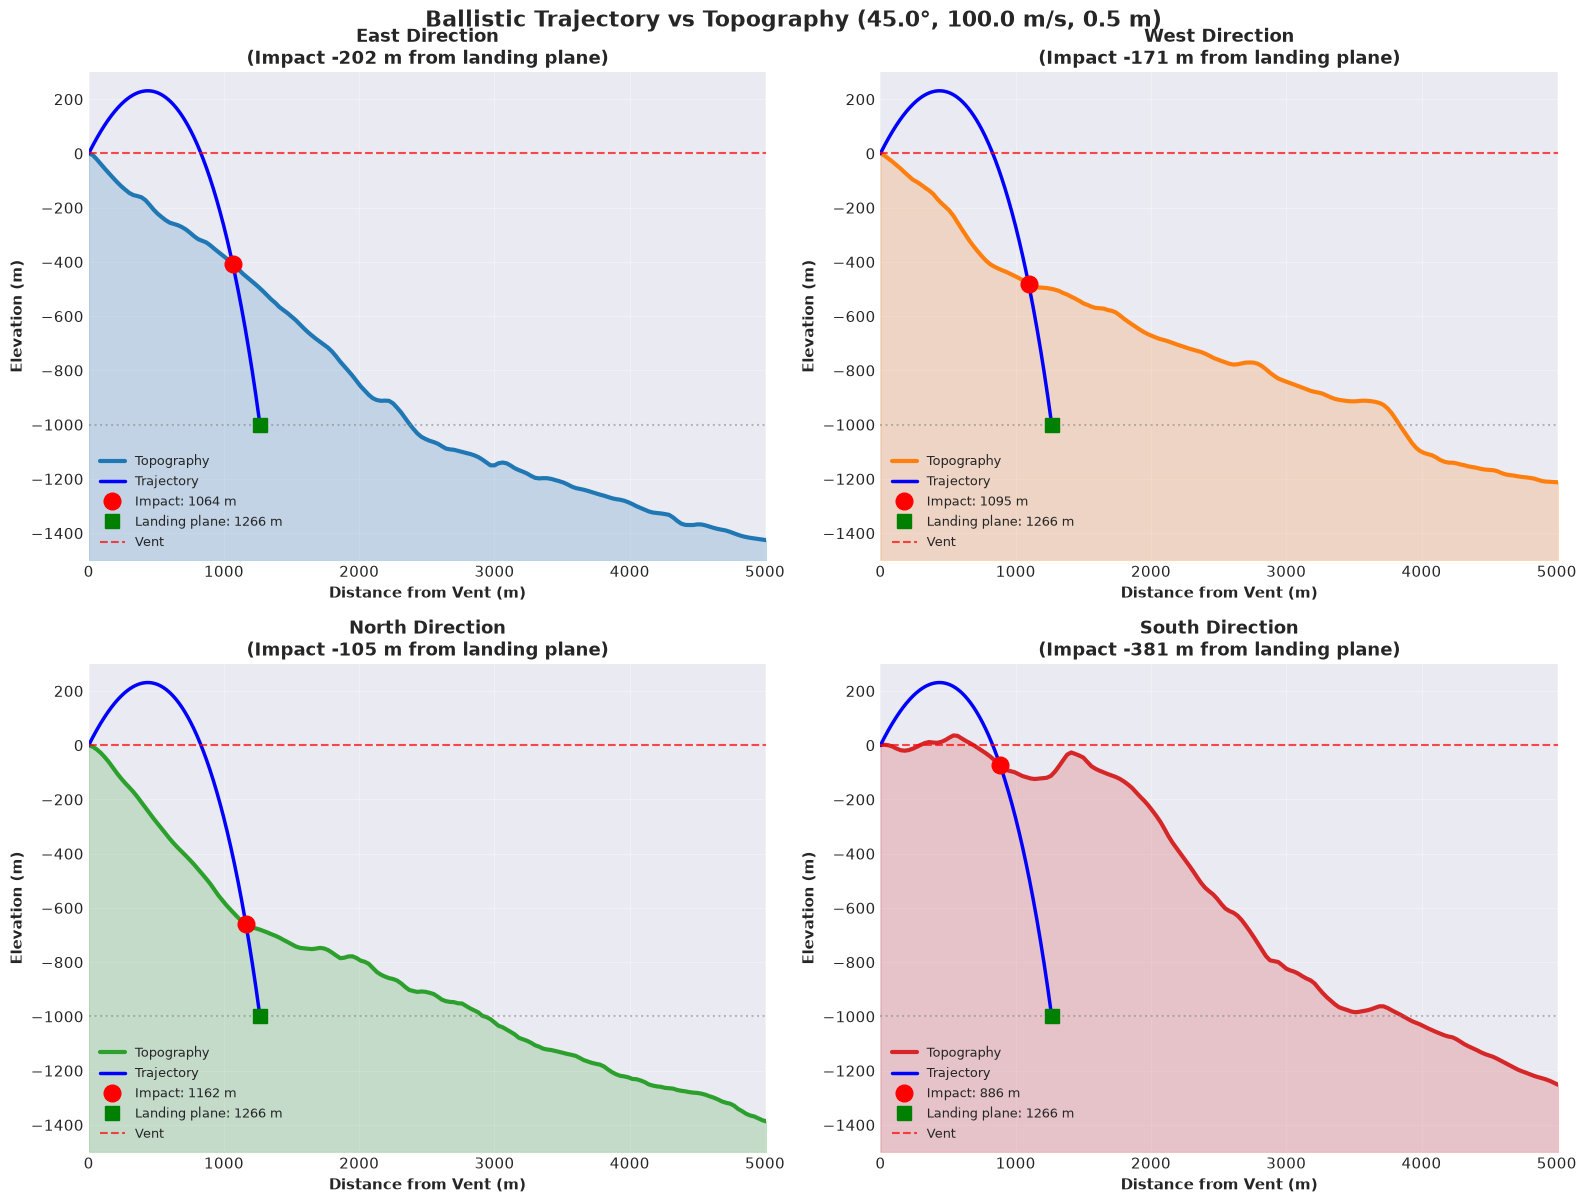


✓ Trajectory-topography comparison plots complete!


In [41]:
# Create detailed plots for each direction
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (dir_name, data) in enumerate(directions.items()):
    ax = axes[idx]
    
    # Plot topography
    ax.plot(data['x'], data['z'], linewidth=3, color=colors[dir_name], 
            label='Topography', zorder=1)
    ax.fill_between(data['x'], data['z'], -1500, alpha=0.2, color=colors[dir_name])
    
    # Plot trajectory
    ax.plot(traj_x, traj_z, 'b-', linewidth=2.5, label='Trajectory', zorder=2)
    
    # Mark impact point
    impact = impact_points[dir_name]
    ax.plot(impact['x'], impact['z'], 'ro', markersize=12, 
            label=f"Impact: {impact['x']:.0f} m", zorder=3)
    
    # Mark landing plane impact
    ax.plot(traj_x[-1], traj_z[-1], 'gs', markersize=10, 
            label=f"Landing plane: {traj_x[-1]:.0f} m", zorder=3)
    
    # Reference lines
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Vent')
    ax.axhline(y=-1000, color='gray', linestyle=':', linewidth=1.5, alpha=0.5)
    
    # Formatting
    ax.set_xlabel('Distance from Vent (m)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Elevation (m)', fontsize=11, fontweight='bold')
    ax.set_title(f'{dir_name} Direction\n(Impact {impact["x"] - traj_x[-1]:+.0f} m from landing plane)', 
                 fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)
    ax.set_xlim(0, max(data['x']))
    ax.set_ylim(-1500, 300)

plt.tight_layout()
plt.suptitle(f'Ballistic Trajectory vs Topography ({angle}°, {velocity} m/s, {diameter} m)', 
             fontsize=16, fontweight='bold', y=1.00)
plt.show()

print("\n✓ Trajectory-topography comparison plots complete!")

**What you should notice:** on flat ground this block lands about 1221 m away, but on the real
slope it lands **much closer** and a different distance in each direction! The danger zone is
**not a perfect circle**.

### Part 2: Does the angle change the impact distance on real terrain?


In [42]:
# Test different angles in the East direction
test_angles = np.arange(25, 76, 5)  # 25° to 75° in 5° steps
test_velocity = 100.0
test_diameter = 0.5

east_data = directions['East']
angle_results = []

print("Testing different ejection angles (East direction):\n")
print(f"{'Angle':<8} {'Landing Plane':<15} {'Topography':<15} {'Max Height'}")
print("-" * 60)

for angle in test_angles:
    traj = eject(angle, test_velocity, test_diameter)
    impact_x, impact_z = find_impact_point(traj[:, 0], traj[:, 1], 
                                           east_data['x'], east_data['z'])
    max_height = np.max(traj[:, 1])
    
    angle_results.append({
        'angle': angle,
        'landing_plane': traj[-1, 0],
        'topography': impact_x,
        'max_height': max_height
    })
    
    print(f"{angle:>5.0f}°   {traj[-1, 0]:>10.1f} m    {impact_x:>10.1f} m    {max_height:>9.1f} m")

angle_results = pd.DataFrame(angle_results)
print("\n✓ Angle parameter study complete")

Testing different ejection angles (East direction):

Angle    Landing Plane   Topography      Max Height
------------------------------------------------------------
   25°       1381.1 m        1100.0 m         86.2 m
   30°       1376.9 m        1123.8 m        119.0 m
   35°       1357.0 m        1127.2 m        154.8 m
   40°       1320.4 m        1104.8 m        192.5 m
   45°       1266.1 m        1064.3 m        231.0 m
   50°       1193.5 m        1003.3 m        269.3 m
   55°       1102.1 m         924.0 m        306.3 m
   60°        991.9 m         830.3 m        341.0 m
   65°        863.4 m         716.8 m        372.4 m
   70°        717.7 m         593.9 m        399.6 m
   75°        555.9 m         450.7 m        421.7 m

✓ Angle parameter study complete


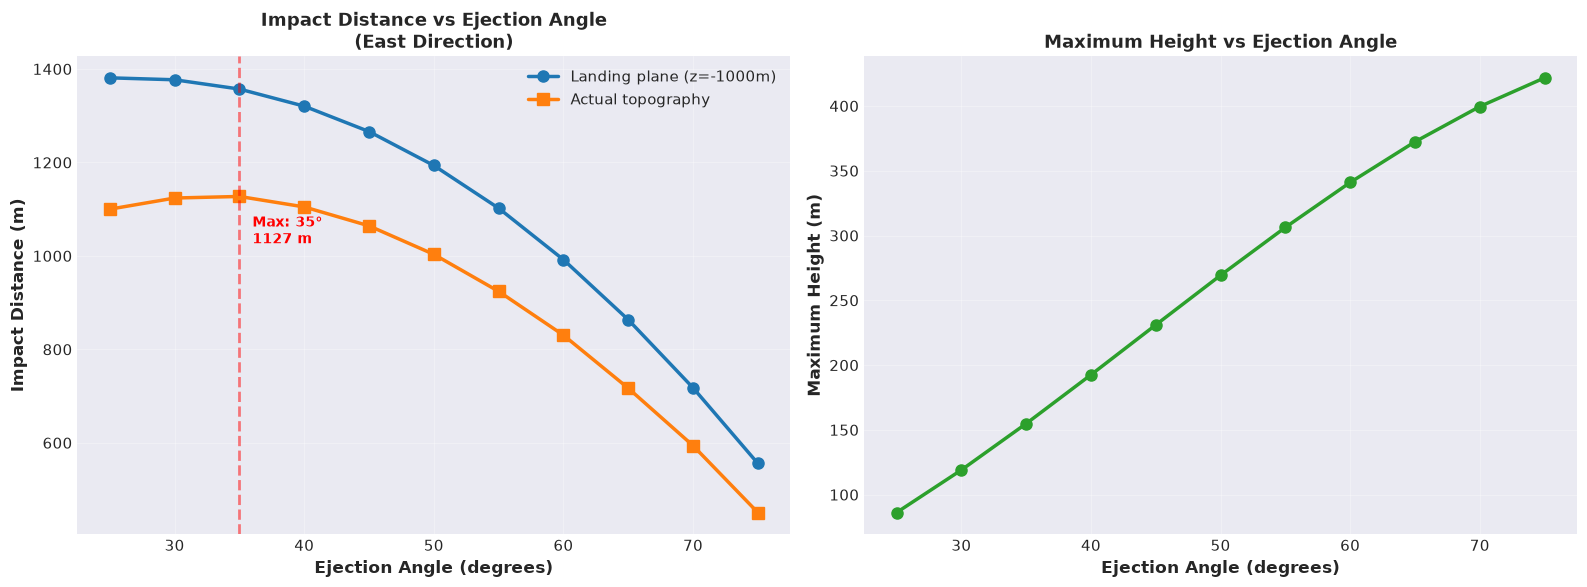


✓ Optimal ejection angle for maximum distance: 35°
  Maximum impact distance: 1127.2 m


In [43]:
# Plot angle study results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Distance vs angle
ax1.plot(angle_results['angle'], angle_results['landing_plane'], 
         'o-', linewidth=2.5, markersize=8, label='Landing plane (z=-1000m)', color='#1f77b4')
ax1.plot(angle_results['angle'], angle_results['topography'], 
         's-', linewidth=2.5, markersize=8, label='Actual topography', color='#ff7f0e')
ax1.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Impact Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Impact Distance vs Ejection Angle\n(East Direction)', 
              fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11)

# Find optimal angle for topography
optimal_idx = angle_results['topography'].idxmax()
optimal_angle = angle_results.loc[optimal_idx, 'angle']
optimal_distance = angle_results.loc[optimal_idx, 'topography']
ax1.axvline(x=optimal_angle, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax1.text(optimal_angle + 1, optimal_distance - 100, 
         f'Max: {optimal_angle:.0f}°\n{optimal_distance:.0f} m',
         fontsize=10, fontweight='bold', color='red')

# Maximum height vs angle
ax2.plot(angle_results['angle'], angle_results['max_height'], 
         'o-', linewidth=2.5, markersize=8, color='#2ca02c')
ax2.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Maximum Height vs Ejection Angle', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✓ Optimal ejection angle for maximum distance: {optimal_angle:.0f}°")
print(f"  Maximum impact distance: {optimal_distance:.1f} m")


## Part 3: The impact-distance map

This is the result you will turn into a map. For each scenario, it gives the **impact distance
in every direction** (the corners of the colored diamonds). The biggest distance is the radius
of your hazard zone.


Configuration            East    North     West    South
--------------------------------------------------------
30°, 100 m/s           1124 m   1248 m   1156 m    804 m
45°, 100 m/s           1064 m   1162 m   1095 m    886 m
60°, 100 m/s            830 m    881 m    860 m    713 m


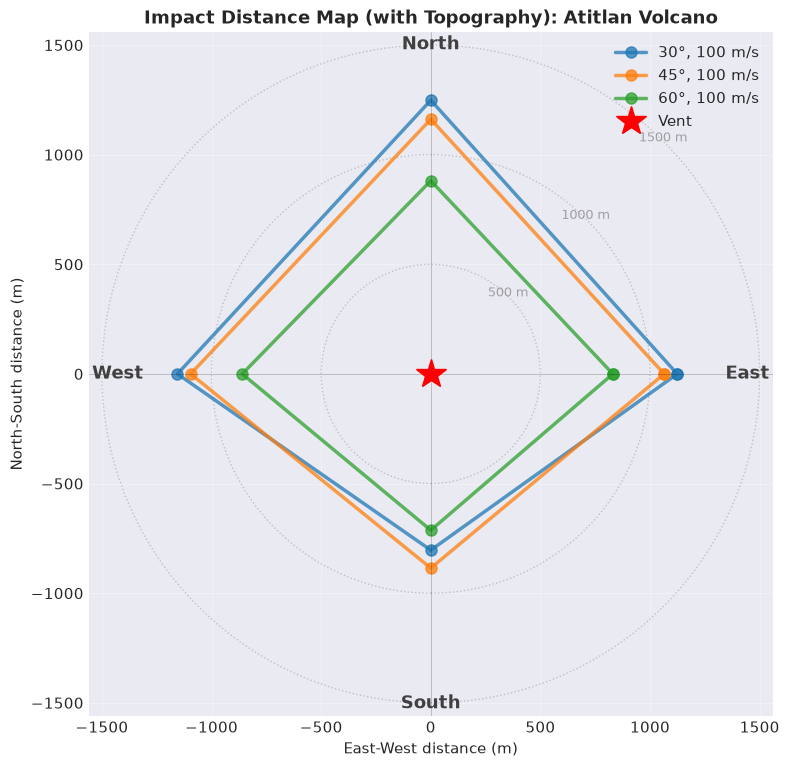


Multi-direction impact map complete.


In [44]:
# Compare several eruption scenarios on one map
test_configs = [
    {'angle': 30, 'velocity': 100, 'diameter': 0.5, 'label': '30°, 100 m/s'},
    {'angle': 45, 'velocity': 100, 'diameter': 0.5, 'label': '45°, 100 m/s'},
    {'angle': 60, 'velocity': 100, 'diameter': 0.5, 'label': '60°, 100 m/s'},
]
config_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Compute impacts, and track the largest so the plot can be sized to the data
all_results, max_impact = [], 0
print(f"{'Configuration':<20}{'East':>9}{'North':>9}{'West':>9}{'South':>9}")
print("-" * 56)
for cfg in test_configs:
    traj = eject(cfg['angle'], cfg['velocity'], cfg['diameter'])
    tx, tz = traj[:, 0], traj[:, 1]
    impacts = {d: find_impact_point(tx, tz, data['x'], data['z'])[0]
               for d, data in directions.items()}
    all_results.append((cfg, impacts))
    max_impact = max(max_impact, *impacts.values())
    print(f"{cfg['label']:<20}{impacts['East']:>7.0f} m{impacts['North']:>7.0f} m"
          f"{impacts['West']:>7.0f} m{impacts['South']:>7.0f} m")

# draw, sized to the data
lim = max_impact * 1.25                       # axis limit sits just beyond the farthest impact
fig, ax = plt.subplots(figsize=(8, 8))

for (cfg, impacts), color in zip(all_results, config_colors):
    xs = [impacts['East'], 0, -impacts['West'], 0, impacts['East']]
    ys = [0, impacts['North'], 0, -impacts['South'], 0]
    ax.plot(xs, ys, 'o-', lw=2.5, ms=8, color=color, alpha=0.75, label=cfg['label'])

ax.plot(0, 0, 'r*', ms=22, zorder=10, label='Vent')

# distance rings: spacing chosen from the data, and only those that fit in view
ring_step = 100 if max_impact < 500 else 200 if max_impact < 1200 else 500
for dist in np.arange(ring_step, lim, ring_step):
    ax.add_patch(plt.Circle((0, 0), dist, fill=False, ec='gray', ls=':', lw=1, alpha=0.4))
    ax.text(dist/np.sqrt(2), dist/np.sqrt(2), f'{dist:.0f} m',
            fontsize=9, color='gray', alpha=0.7, ha='center')

# N/E/S/W labels pinned just inside the rim
r = lim * 0.99
for txt, (x, y, ha, va) in {'North': (0,  r, 'center', 'top'),
                            'South': (0, -r, 'center', 'bottom'),
                            'East':  ( r, 0, 'right', 'center'),
                            'West':  (-r, 0, 'left', 'center')}.items():
    ax.text(x, y, txt, fontsize=13, fontweight='bold', color='0.25', ha=ha, va=va)

ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal',
       xlabel='East-West distance (m)', ylabel='North-South distance (m)')
ax.set_title('Impact Distance Map (with Topography): Name of Volcano', fontweight='bold') # don't forget to add the name of your volcano
ax.axhline(0, color='k', lw=0.5, alpha=0.3); ax.axvline(0, color='k', lw=0.5, alpha=0.3)
ax.grid(True, alpha=0.3); ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

print("\nMulti-direction impact map complete.")

> **CHECK:** you should see a diamond-shaped map with the vent (red star) in the center, and a
> printed table of impact distances for each scenario.

**Example (45°, 100 m/s, 0.5 m):** North ≈ 442 m, South ≈ 620 m, East ≈ 339 m, West ≈ 302 m.
The maximum (620 m) is the radius you draw in QGIS.



## Part 4: Record your impact distances

**Your turn:** in the cell below, change the three numbers marked `<-- change this`, then run it.
It prints a tidy table of the four impact distances. 

In [45]:
# ===== CHANGE THESE THREE NUMBERS TO YOUR OWN SCENARIO =====
my_angle    = 30.0    # degrees   <-- change this
my_velocity = 100.0   # m/s       <-- change this
my_diameter = 0.5     # m         <-- change this
# ===========================================================

traj = eject(my_angle, my_velocity, my_diameter)
tx, tz = traj[:, 0], traj[:, 1]

results = []
for name, data in directions.items():
    impact_x, _ = find_impact_point(tx, tz, data['x'], data['z'])
    results.append({'direction': name, 'impact_distance_m': round(impact_x, 1)})

results = pd.DataFrame(results)
max_distance = results['impact_distance_m'].max()

print(f"Scenario: {my_angle}°, {my_velocity} m/s, {my_diameter} m block\n")
print(results.to_string(index=False))
print(f"\nMAXIMUM impact distance = {max_distance:.0f} m   (use this as your buffer radius)")

Scenario: 30.0°, 100.0 m/s, 0.5 m block

direction  impact_distance_m
     East             1123.8
     West             1155.7
    North             1248.2
    South              803.7

MAXIMUM impact distance = 1248 m   (use this as your buffer radius)



## Part 5: Export your impact points for QGIS

The cell below turns your four impact distances into **map points** (longitude, latitude) around
a vent that you choose, and saves them as `impact_points.csv`. QGIS can read this file directly.

**Your turn:** in the cell below, change the two lines marked `<-- change this` to your volcano's
latitude and longitude. Also make sure the three inputs in Part 4 match the scenario you want.


In [46]:
# ===== CHANGE THIS TO YOUR OWN VOLCANO (decimal degrees) =====
vent_lat = -8.5420   # latitude   (negative = South)   <-- change this
vent_lon = 122.7750   # longitude  (negative = West)    <-- change this

# bearings: degrees clockwise from North
bearings = {'North': 0, 'East': 90, 'South': 180, 'West': 270}

traj = eject(my_angle, my_velocity, my_diameter)
tx, tz = traj[:, 0], traj[:, 1]

rows = []
for name, bearing in bearings.items():
    data = directions[name]
    impact_x, _ = find_impact_point(tx, tz, data['x'], data['z'])
    br = np.radians(bearing)
    # short-distance offset: meters -> degrees (accurate to < 1 m at these scales)
    dlat = (impact_x * np.cos(br)) / 111320.0
    dlon = (impact_x * np.sin(br)) / (111320.0 * np.cos(np.radians(vent_lat)))
    rows.append({'direction': name, 'distance_m': round(impact_x, 1),
                 'lon': round(vent_lon + dlon, 6),
                 'lat': round(vent_lat + dlat, 6)})

# include the vent itself
rows.append({'direction': 'Vent', 'distance_m': 0.0, 'lon': vent_lon, 'lat': vent_lat})

points = pd.DataFrame(rows)
points.to_csv('impact_points.csv', index=False)
print(points.to_string(index=False))
print("\nSaved -> impact_points.csv  (open this file in QGIS)")

direction  distance_m        lon       lat
    North      1248.2 122.775000 -8.530787
     East      1123.8 122.785209 -8.542000
    South       803.7 122.775000 -8.549220
     West      1155.7 122.764502 -8.542000
     Vent         0.0 122.775000 -8.542000

Saved -> impact_points.csv  (open this file in QGIS)


> **CHECK:** a file called `impact_points.csv` appears next to this notebook, with the columns
> `direction, distance_m, lon, lat`.



## Part 6: Add to hazard map in QGIS

These steps are done in the **QGIS application**.

### Set up QGIS

1. Open **QGIS** and start a **New Project**.
2. Add the points: **Layer --> Add Layer --> Add Delimited Text Layer**, open `impact_points.csv`,
   choose **Point coordinates**, set **X = lon**, **Y = lat**, **CRS = EPSG:4326**.
3. Set a **metric CRS**: click the CRS code at the bottom-right of QGIS and choose the correct
   **UTM zone** for your volcano (units = meters).

> **Why the CRS matters:** in a degrees CRS, a buffer of "620" means 620 *degrees* and that is wrong! In a
> UTM (meters) CRS, "620" correctly means 620 meters. (Licancabur is EPSG:32719, UTM zone 19S.)

### Method 1: Buffer (a circle)

1. Take your **maximum** impact distance from Part 4 (example: 620 m).
2. Open **Vector --> Geoprocessing Tools --> Buffer**.
3. Set **Input layer** = the vent point. Set **Distance** = your maximum (example: `620`).
4. Click **Run**, then style it: red fill, about 40% transparent, with a clear outline.

### Method 2: Directional polygon (a diamond). *(optional).*

1. The `impact_points.csv` already has the four directional points.
2. With that points layer loaded, run **Vector --> Geoprocessing Tools --> Convex hull**.
3. Style the new polygon the same way. It reaches farther in some directions, like the real
   slope.

### Finish the map

1. Add a **basemap** (for example, OpenStreetMap) so towns and roads show.
2. Open **Project --> New Print Layout**. Add a title, a legend, a scale bar, and a north arrow.
3. Write the scenario on the map, for example:
   *"Ballistic hazard: 45°, 100 m/s, 0.5 m block --> maximum reach 620 m."*
4. Export it: **Layout ▸ Export as PDF** (or as an image).



## Check for your volcano!

-  [ ] My chosen inputs (angle, velocity, diameter).
-  [ ] The four impact distances from Part 4.
-  [ ] A buffer (circle) hazard map in QGIS.
-  [ ] A finished map with a basemap, PDC and lahar hazards data, a legend, a scale bar, and a caption with the scenario.
-  [ ] The map exported as a PDF or image.



## One more thing: this is **ONE** scenario, not the whole story

The map you built uses **one** eruption! One angle, one speed, one block size. That is a good
first estimate, but a real volcano does not erupt in exactly one way. Real blocks also collide,
spin, and ride the gas jet, so the true danger zone is uneven.

Professional hazard assessment runs **many** eruptions and reports the **chance** of reaching
each distance. This is called a **probabilistic** hazard map.

- A single circle answers *"how far can a block go?"*
- A probabilistic map answers *"how likely is each distance?"*, which is what people planning
  for safety actually need to know.


## If something goes wrong

| Problem | Try this |
|---------|----------|
| The buffer is very small or very large | Your CRS is in degrees. Set a UTM (meters) CRS, then run Buffer again. |
| The CSV points do not appear in QGIS | Check **X = lon** and **Y = lat** (not swapped), and **CRS = EPSG:4326**. If the **Add** button is gray, set the CRS first. |
| A plot is empty | Run every cell from the top! A later cell needs the results of an earlier one. |
